# Conditional operations through `qm-backend`

This notebook submits **two-round fast reset** on q5. You build and draw the
circuit locally, then submit that same construction code to the server over SSH.
There is no separately maintained server script.

The notebook kernel needs the CQT-qibo fork with conditional operations, IPython,
pandas and matplotlib. The QM stack runs in the server's isolated
`test-qm-backend/.venv`, using the `eo-qm-backend` CQT-qibo fork installed there.
The local kernel does not load the hardware backend or execute the circuit.

Run the setup and circuit cells, then the explicit submission cell only when you
want to launch a real job. There is no simulation or automatic fallback.
T-gate teleportation, quantum teleportation and repetition can be added later
using the same submission mechanism.

In [18]:
# Local notebook tools. Circuit construction also uses the local CQT-qibo fork.
import json
import re
import shlex
import subprocess
import time
import uuid

import pandas as pd
import matplotlib.pyplot as plt
from IPython.core.magic import register_cell_magic


@register_cell_magic
def server_code(line, cell):
    """Store remote-only Python source without executing it locally."""
    get_ipython().user_ns[line.strip()] = cell
    print(f"Stored {line.strip()}; nothing executed or submitted.")


@register_cell_magic
def circuit_code(line, cell):
    """Build the circuit locally and retain the exact same source for Slurm."""
    namespace = get_ipython().user_ns
    name = line.strip()
    namespace.pop(name, None)
    exec(compile(cell, "<notebook circuit construction>", "exec"), namespace)
    namespace[name] = cell
    print(f"Circuit built locally; source stored as {name}. No job submitted.")

In [19]:
# SSH / Slurm transport. Only submit_notebook_job() submits a job.
SSH_HOST = "cqt-paul-server-nqch-deploy"
REMOTE_DIR = "/mnt/home/nqch-deploy/test-qm-backend"
REMOTE_PYTHON = f"{REMOTE_DIR}/.venv/bin/python"
PLATFORMS_ROOT = "/mnt/scratch/qibolab_platforms_nqch"
SLURM_LOGS = f"{REMOTE_DIR}/slurm_logs"
RESULT_PREFIX = "QM_BACKEND_RESULT="
TERMINAL_STATES = {
    "COMPLETED", "FAILED", "CANCELLED", "TIMEOUT", "OUT_OF_MEMORY",
    "NODE_FAIL", "BOOT_FAIL", "DEADLINE", "PREEMPTED", "REVOKED",
}


def _ssh(command, *, input_text=None):
    completed = subprocess.run(
        ["ssh", "-o", "BatchMode=yes", "-o", "ConnectTimeout=10", SSH_HOST, command],
        input=input_text if input_text is not None else "",
        capture_output=True, text=True, timeout=45,
    )
    if completed.returncode:
        raise RuntimeError(f"SSH command failed: {completed.stderr.strip()}")
    return completed.stdout


def _slurm_state(job_id):
    rows = _ssh(f"sacct -X -n -P -j {shlex.quote(str(job_id))} --format=JobIDRaw,State")
    for row in rows.splitlines():
        fields = row.split("|", 1)
        if len(fields) == 2 and fields[0].strip() == str(job_id):
            return fields[1].strip().split()[0].rstrip("+")
    queued = _ssh(f"squeue -h -j {shlex.quote(str(job_id))} -o %T").strip()
    return queued.splitlines()[0] if queued else "UNKNOWN"


def submit_notebook_job(source):
    """Send the stored cell verbatim to sbatch's stdin; no server .py file."""
    delimiter = "NOTEBOOK_PYTHON_" + uuid.uuid4().hex
    batch = (
        "#!/bin/bash\n"
        f"export QM_BACKEND_PLATFORMS={shlex.quote(PLATFORMS_ROOT)}\n"
        f"exec {shlex.quote(REMOTE_PYTHON)} -u - <<'{delimiter}'\n"
        + source + ("" if source.endswith("\n") else "\n")
        + delimiter + "\n"
    )
    command = shlex.join([
        "sbatch", "--parsable", "--partition=sinq20", "--job-name=qm_notebook_fast_reset",
        f"--chdir={REMOTE_DIR}", "--time=00:30:00",
        f"--output={SLURM_LOGS}/slurm-notebook-fast-reset-%j.out",
        f"--error={SLURM_LOGS}/slurm-notebook-fast-reset-%j.err",
    ])
    # Slurm retains the submitted program internally. Re-editing the notebook
    # after submission does not change the running job.
    job_id = _ssh(command, input_text=batch).strip().split(";", 1)[0]
    if not re.fullmatch(r"\d+", job_id):
        raise RuntimeError(f"Could not parse Slurm job ID: {job_id!r}")
    print(f"Submitted Slurm job {job_id}", flush=True)
    return job_id

## Fast reset — build and draw the circuit locally

Prepare $|+\rangle$, measure and conditionally apply X, then repeat the reset
before the final measurement. On the server, logical qubit 0 will use physical
qubit **q5**, with **1,000 shots**.

`%%circuit_code fast_reset_circuit_source` runs the construction cell locally,
so `c` and its measurement handles are available in the notebook. It also stores
that exact code for submission. This cell contains imports, circuit
construction and `c.draw()`, so running it also displays the circuit immediately.
Backend selection and `c(nshots=...)` remain in the remote cells below. The
stored code includes `c.draw()`, so the drawing also appears in the Slurm output.

Edit and rerun the construction cell whenever you change the circuit. The local
drawing and the submitted construction code then reflect the same definition.
Changes made to `c` in other cells are local only; put gate edits in this cell.
The result and plotting cells identify measurements by their `register_name`
values (`before_reset`, `before_reset2`, `after_reset`). Renaming the Python
measurement variables does not change those results or require plotting changes.


In [20]:
%%circuit_code fast_reset_circuit_source
from qibo import Circuit, gates

c = Circuit(1)
c.add(gates.H(0))  # prepare |+> so both feedback outcomes occur

measured_bit_before_reset_1 = c.add(gates.M(0, collapse=True, register_name="before_reset"))
c.add(gates.IfElse(
    measured_bit_before_reset_1.is_one(), 
    then_do=gates.X(0)))

measured_bit_before_reset2 = c.add(gates.M(0, collapse=True, register_name="before_reset2"))
c.add(gates.IfElse(
    measured_bit_before_reset2.is_one(), 
    then_do=gates.X(0)))
c.add(gates.M(0, register_name="after_reset"))

c.draw()


0: ─H─M─if[─X─][─]─M─if[─X─][─]─M─
Circuit built locally; source stored as fast_reset_circuit_source. No job submitted.


### Hardware setup and execution — stored for the server only

The next two cells store the server setup and execution code without running
it on your Mac. At submission, the notebook joins these pieces in this order:

1. Select `qm-backend`, platform `sinq20`, and physical placement q5.
2. Build the circuit using the exact construction cell above.
3. Run it for 1,000 shots and write its results to the Slurm output.

After a successful hardware run, the code writes the measurement counts as JSON
text in the `.out` file. The notebook retrieves those counts over SSH for plotting.

In [21]:
%%server_code fast_reset_setup_source
import json
import qibo

qibo.set_backend("qm-backend",
                platform="sinq20",
                physical_qubits=("q5",))

Stored fast_reset_setup_source; nothing executed or submitted.


In [22]:
%%server_code fast_reset_execution_source

result = c(nshots=1000)
print(f"QM job ID: {result.qm_job_id}", flush=True)
print("\nFinal counts:", result.frequencies(), flush=True)
print("\nAll measurement registers:", result.register_frequencies(), flush=True)

# Preserve shot correlations, with register order stated explicitly.
registers = ("before_reset", "before_reset2", "after_reset")
payload = {
    "qm_job_id": result.qm_job_id,
    "shots": result.nshots,
    "register_counts": {name: dict(counts) for name, counts in result.register_frequencies().items()},
    "joint_counts": dict(result.joint_frequencies(registers=registers)),
    "final_counts": dict(result.frequencies()),
}
print("QM_BACKEND_RESULT=" + json.dumps(payload), flush=True)

Stored fast_reset_execution_source; nothing executed or submitted.


## Retrieve results and logs

These functions wait for the submitted job and retrieve its `.out` and `.err`
files from `slurm_logs/`. Measurement data comes from the execution cell's JSON
line, using Qibo register order. The adapter below supplies the same counts
expected by the existing plots.

A result payload is read whenever it is present, independently of the Slurm
status. The actual Slurm status is still reported. If no payload is present,
`measurement_results` is `None`; inspect `raw_logs`. A successful Slurm exit
without a payload is reported as a retrieval error.

In [23]:
def _fast_reset_measurements(payload):
    registers = payload["register_counts"]
    before = registers["before_reset"]
    before2 = registers["before_reset2"]
    after = registers["after_reset"]
    return {
        "joint_counts": {"->".join(key.split()): count for key, count in payload["joint_counts"].items()},
        "before_reset_counts": before,
        "before_reset2_counts": before2,
        "after_reset_counts": after,
        "first_reset_zero_count": before2.get("0", 0),
        "final_zero_count": after.get("0", 0),
    }


def collect_fast_reset_job(job_id):
    """Retrieve a job again without submitting anything; useful after interruption."""
    job_id = str(job_id)
    status = _slurm_state(job_id)
    log_base = f"{SLURM_LOGS}/slurm-notebook-fast-reset-{job_id}"
    # Slurm may record completion just before the files become visible.
    for attempt in range(5):
        try:
            stdout = _ssh(f"cat {shlex.quote(log_base + '.out')}")
            stderr = _ssh(f"cat {shlex.quote(log_base + '.err')}")
            break
        except RuntimeError:
            if attempt == 4:
                raise
            time.sleep(2)
    records = [line[len(RESULT_PREFIX):] for line in stdout.splitlines() if line.startswith(RESULT_PREFIX)]
    payload = json.loads(records[-1]) if records else None
    retrieval_error = None
    if status == "COMPLETED" and payload is None:
        retrieval_error = "Job completed but no backend result payload was found in stdout."
    return {
        "job_id": job_id, "status": status,
        "raw_logs": {"stdout": stdout, "stderr": stderr},
        "backend_result": payload,
        "measurement_results": _fast_reset_measurements(payload) if payload is not None else None,
        "retrieval_error": retrieval_error,
    }


def wait_for_fast_reset_job(job_id, poll_seconds=10, max_wait_seconds=7200):
    """Wait only: this function never submits or cancels a job."""
    started = time.monotonic()
    previous_state = None
    while True:
        status = _slurm_state(job_id)
        if status != previous_state:
            print(f"Job {job_id}: {status}", flush=True)
            previous_state = status
        if status in TERMINAL_STATES:
            return collect_fast_reset_job(job_id)
        if time.monotonic() - started >= max_wait_seconds:
            raise TimeoutError(f"Stopped waiting for job {job_id}; it was not cancelled. Use collect_fast_reset_job({job_id!r}) later.")
        time.sleep(poll_seconds)

## Submit — running the next cell launches a real hardware job

The next cell combines the stored backend setup, circuit construction and
execution code into `fast_reset_source`, then sends that program to Slurm over
SSH using the server `.venv` and `sinq20` partition. Slurm log files (`.out` and
`.err`) are written in `slurm_logs/`.

Run the construction and remote-code cells after editing them, then submit
**once per desired job**. Its job ID is saved before waiting. If you interrupt
the wait, the job continues; retrieve it later with
`fast_reset_job = collect_fast_reset_job(fast_reset_job_id)` instead of resubmitting.

In [ ]:
# Submit slurm job
fast_reset_source = "\n\n".join((
    fast_reset_setup_source,
    fast_reset_circuit_source,
    fast_reset_execution_source,
))
fast_reset_job_id = submit_notebook_job(fast_reset_source)
fast_reset_job = wait_for_fast_reset_job(fast_reset_job_id)
print("Slurm state:", fast_reset_job["status"])
if fast_reset_job["measurement_results"] is None:
    print(fast_reset_job["retrieval_error"] or "No hardware results returned.")
    print("\n--- stdout ---\n" + fast_reset_job["raw_logs"]["stdout"])
    print("\n--- stderr ---\n" + fast_reset_job["raw_logs"]["stderr"])
fast_reset_job["measurement_results"]

Submitted Slurm job 67592
Job 67592: RUNNING
Job 67592: FAILED
Slurm state: FAILED
No hardware results returned.

--- stdout ---
2026-11-06 21:49:49,856 - qm - INFO     - Starting session: f7503e69-d2ba-481d-8439-31a1c0d9d09b
[Qibo 0.3.7|INFO|2026-11-06 21:49:51]: Using qm-backend (sinq20) backend on /CPU:0
0: ─H─M─if[─X─][─]─M─if[─X─][─]─M─
2026-11-06 21:51:51,662 - qm - ERROR    - Failed to detect to QuantumMachines server, failed to connect to cluster 'Incredible_Horse'. Tried connecting to 192.168.88.246:80.
Errors:
192.168.88.246:80: timed out
Traceback (most recent call last):
  File "/mnt/home/nqch-deploy/test-qm-backend/.venv/lib/python3.12/site-packages/httpx/_transports/default.py", line 101, in map_httpcore_exceptions
    yield
  File "/mnt/home/nqch-deploy/test-qm-backend/.venv/lib/python3.12/site-packages/httpx/_transports/default.py", line 250, in handle_request
    resp = self._pool.handle_request(req)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/mnt/home/nqch-depl

In [ ]:
#fast_reset_job = collect_fast_reset_job("67592")

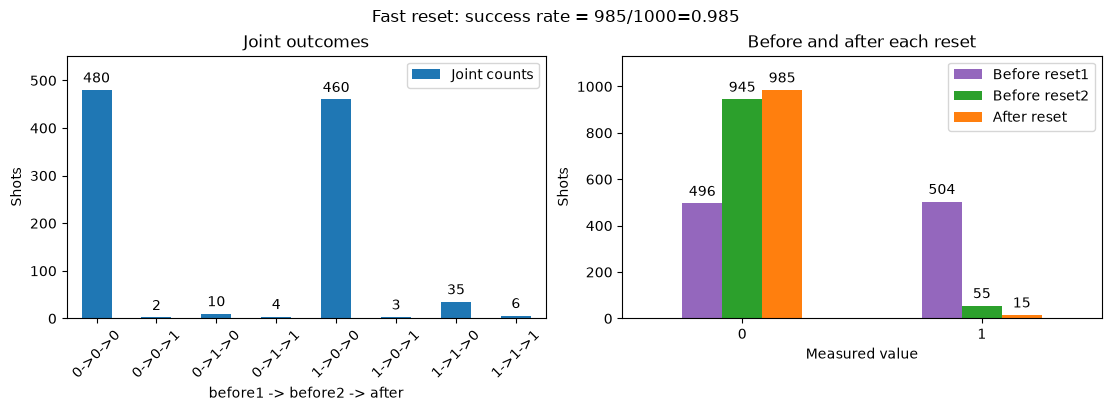

In [28]:
# Plotting
results = fast_reset_job["measurement_results"]
if results is None:
    raise ValueError("No measurement results found; inspect fast_reset_job['raw_logs'].")

transitions = ["->".join(f"{value:03b}") for value in range(8)]  # before_reset1 -> before_reset2 -> after_reset
joint_counts = pd.DataFrame(
    {"Joint counts": [results["joint_counts"].get(label, 0) for label in transitions]},
    index=transitions,
)
before_after_counts = pd.DataFrame(
    {
        "Before reset1": [results["before_reset_counts"].get(bit, 0) for bit in ("0", "1")],
        "Before reset2": [results["before_reset2_counts"].get(bit, 0) for bit in ("0", "1")],
        "After reset": [results["after_reset_counts"].get(bit, 0) for bit in ("0", "1")],
    },
    index=["0", "1"],
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
shots = int(joint_counts["Joint counts"].sum())
succ_rate = results['final_zero_count']/shots
fig.suptitle(f"Fast reset: success rate = {results['final_zero_count']}/{shots}={succ_rate}")
joint_counts.plot.bar(ax=axes[0], color="tab:blue", rot=45, legend=True)
before_after_counts.plot.bar(
    ax=axes[1], color=["tab:purple", "tab:green", "tab:orange"], rot=0, legend=True
)
axes[0].set(title="Joint outcomes", xlabel="before1 -> before2 -> after", ylabel="Shots")
axes[1].set(title="Before and after each reset", xlabel="Measured value", ylabel="Shots")
for ax in axes:
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)
    ax.margins(y=0.15)
plt.show()

**How to read the fast-reset plots**

- **Left (blue):** Each bar counts a three-measurement sequence from the same
  shot: before reset 1 → before reset 2 → after reset 2. For example, `1→0→0`
  means the first correction left 0, which remained 0 after the second round.
- **Right:** Purple shows the first measurement, green the second, and orange
  the final measurement. A taller orange bar at 0 means more successful final
  resets. The title reports the final-zero count divided by all returned shots.

These plots require successful hardware results retrieved above. The notebook
contains no saved replacement results for the currently unreachable QM server.